In [52]:
import numpy as np
import matplotlib.pyplot as plt

In [53]:
# Unidades

## Comprimento
um = 1e-6
nm = 1e-9

## Frequência

GHz = 1e9
THz = 1e12

## Tempo

ns = 1e-9
ps = 1e-12

# Constantes

pi = np.pi
c = 3e8 # m/s
lambda_ = 1.55*um
f_ = c/lambda_

# Mapas de cores

cmap1 = plt.cm.viridis
cmap2 = plt.cm.plasma
cmap3 = plt.cm.inferno
cmap4 = plt.cm.magma
cmap5 = plt.cm.coolwarm
cmap6 = plt.cm.turbo

# Acopladores direcionais #

Um acoplador direcional é um dispositivo fotônico com a seguinte estrutura:

<p align="center">
  <img src="Imagens/Acoplador direcional.jpg" width="550" />
</p>

A matriz de transferência de um acoplador direcional é

$$
\begin{bmatrix}
b_1 \\
b_2
\end{bmatrix}
=
\begin{bmatrix}
r & -j\kappa \\
-j\kappa & r
\end{bmatrix}
\begin{bmatrix}
a_1 \\
a_2
\end{bmatrix}
\,,
$$

onde $r$ é o fator de auto-acoplamento e $\kappa$ é o fator de acoplamento cruzado. $r^2$ é a razão de transmissão direta de potência óptica e $\kappa^2$ é a razão de acoplamento de potência óptica de um guia para o outro, pelo princípio da conservação de energia: $r^2+\kappa^2=1$. Em um acoplador direcional:

$$\kappa^2 = \sin^2{\left(\frac{\pi\Delta n}{\lambda}L_c+\phi_0\right)}\,,$$

Em geral, $\phi_0\approx 0$, então:

$$\kappa^2 = \sin^2{\left(\frac{\pi\Delta n}{\lambda}L_c\right)}\,.$$

O valor de $L_c$ necessário para se obter um determinado $\kappa$ é:

$$L_c = \frac{\lambda}{2\pi\Delta n}\cos^{-1}{\left(1-2\kappa^2\right)}\,,$$

para se obter $\kappa=1$, é necessário que:

$$L_c(\kappa = 1) = \frac{\lambda}{2\Delta n} = L_x\,.$$

In [54]:
def kappa2(Lc, dn):
    return np.sin(pi * dn * Lc / lambda_)**2

def Lc(kappa, dn):
    arccos = np.arccos(1-2*kappa**2)
    A = lambda_/(2*pi*dn)
    return A*arccos

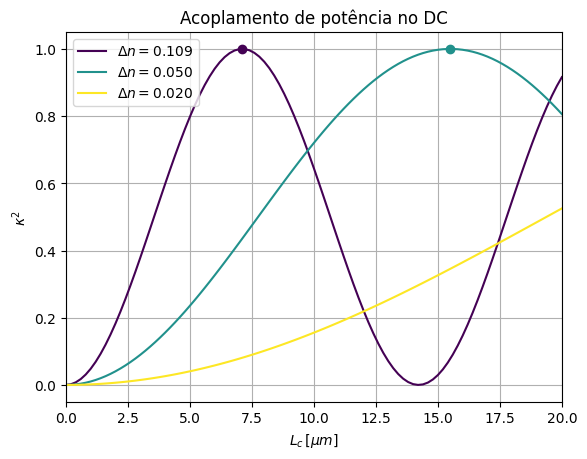

In [55]:
dn_array = [0.109, 0.050, 0.020]
Lc_array = np.linspace(0, 20, 101)*um

N = len(dn_array)
k = 0

for dn in dn_array:
    plt.plot(lambda_/(2*dn)/um, 1, color=cmap1(k/(N-1)), marker = 'o')
    plt.plot(Lc_array/um, kappa2(Lc_array, dn), label = r'$\Delta n = %.3f$' %dn, color=cmap1(k/(N-1)))
    k += 1
plt.xlabel(r'$L_c\,[\mu m]$')
plt.ylabel(r'$\kappa^2$')
plt.grid(True)
plt.legend(loc = 'best')
plt.xlim(Lc_array[0]/um, Lc_array[-1]/um)
plt.title('Acoplamento de potência no DC')
plt.show()

In [56]:
kappaq = 0.5
dn = dn_array[0]

kappa = np.sqrt(kappaq)
Lc_kappa = Lc(kappa, dn)

print('O comprimento para obter \u03BA² = %.2f com \u0394n = %.3f é Lc = %.3f \u00B5m.' %(kappaq, dn, Lc_kappa/um))

O comprimento para obter κ² = 0.50 com Δn = 0.109 é Lc = 3.555 µm.
